In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(10)

In [2]:
# ---------------- Common parameters ----------------
fc = 2.4e9              # Carrier frequency: 2.4 GHz
c = 3e8                 # Speed of light (m/s)
Pt_dBm = 20             # Transmit power in dBm
n = 3.5                 # Path-loss exponent
d0 = 1                  # Reference distance (m)
PL_d0 = 20*np.log10(4*np.pi*d0*fc/c)  # Free-space path loss at d0
sigma_shadow = 6        # Shadowing standard deviation in dB

# =====================================================
# 1. LARGE-SCALE FADING
# Path loss + log-normal shadowing versus distance
# =====================================================

In [3]:
distance = np.linspace(1, 1000, 1000)   # Distance from transmitter in meters

# Log-distance path-loss model
path_loss_dB = PL_d0 + 10*n*np.log10(distance/d0)

# Shadowing: zero-mean Gaussian variation in dB
shadowing_dB = np.random.normal(0, sigma_shadow, size=distance.shape)

# Total large-scale loss
large_scale_loss_dB = path_loss_dB + shadowing_dB

# Received power due to large-scale fading only
Pr_large_scale_dBm = Pt_dBm - large_scale_loss_dB

# =====================================================
# 2. SMALL-SCALE FADING
# Rayleigh fading over time
# =====================================================

In [4]:
fs = 1000               # Sampling frequency (Hz)
time = np.arange(0, 1, 1/fs)  # 1 second of channel variation

# Rayleigh fading: h = h_I + j*h_Q, each Gaussian
h_I = np.random.normal(0, 1/np.sqrt(2), size=time.shape)
h_Q = np.random.normal(0, 1/np.sqrt(2), size=time.shape)
h = h_I + 1j*h_Q

# Small-scale fading gain in dB
small_scale_gain_dB = 20*np.log10(np.abs(h))

# =====================================================
# 3. COMBINED RECEIVED POWER
# Large-scale loss + small-scale fading
# =====================================================

In [5]:
# Use the large-scale loss at a fixed distance, e.g., 100 m
d_fixed = 100
idx = np.argmin(np.abs(distance - d_fixed))
large_scale_loss_fixed = large_scale_loss_dB[idx]

# Received power including both fading effects
Pr_total_dBm = Pt_dBm - large_scale_loss_fixed + small_scale_gain_dB

# =====================================================
# PLOTS
# =====================================================

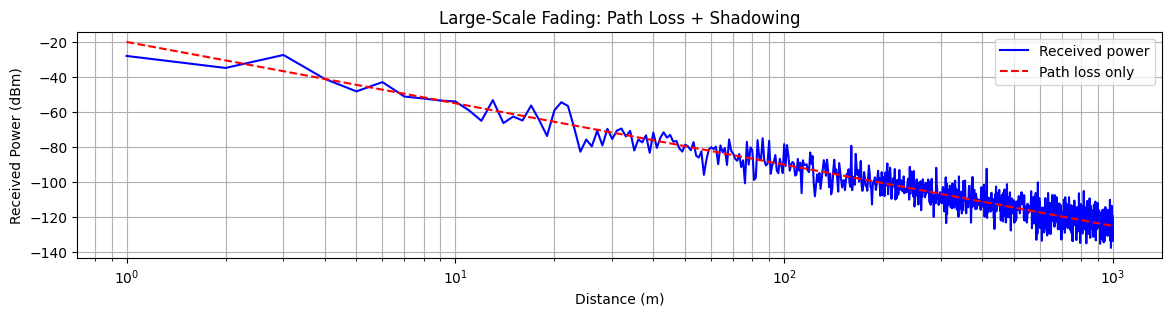

In [6]:
plt.figure(figsize=(14, 10))

# Plot 1: Large-scale fading
plt.subplot(3, 1, 1)
plt.semilogx(distance, Pr_large_scale_dBm, 'b', label='Received power')
plt.semilogx(distance, Pt_dBm - path_loss_dB, 'r--', label='Path loss only')
plt.xlabel('Distance (m)')
plt.ylabel('Received Power (dBm)')
plt.title('Large-Scale Fading: Path Loss + Shadowing')
plt.grid(True, which='both')
plt.legend()

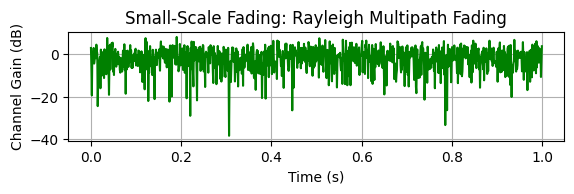

In [7]:
# Plot 2: Small-scale fading
plt.subplot(3, 1, 2)
plt.plot(time, small_scale_gain_dB, 'g')
plt.xlabel('Time (s)')
plt.ylabel('Channel Gain (dB)')
plt.title('Small-Scale Fading: Rayleigh Multipath Fading')
plt.grid(True)

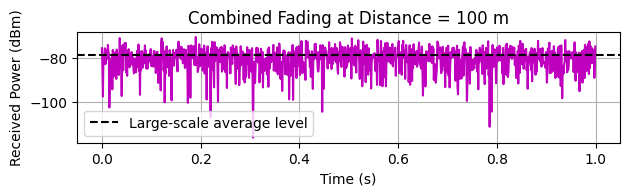

In [8]:
# Plot 3: Combined fading
plt.subplot(3, 1, 3)
plt.plot(time, Pr_total_dBm, 'm')
plt.axhline(Pt_dBm - large_scale_loss_fixed, color='k', linestyle='--',
            label='Large-scale average level')
plt.xlabel('Time (s)')
plt.ylabel('Received Power (dBm)')
plt.title(f'Combined Fading at Distance = {d_fixed} m')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

The script uses the log-distance path-loss model:

## 𝑃𝐿(𝑑) = 𝑃𝐿(𝑑0) + 10𝑛log(𝑑/𝑑0) + 𝑋𝜎

Rayleigh small-scale fading:

## ℎ = ℎ𝐼 + 𝑗ℎ𝑄



### where ℎ𝐼 and ℎ𝑄  are independent zero-mean Gaussian random variables. The magnitude ∣ℎ∣ follows a Rayleigh distribution when there is no dominant line-of-sight component.